In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from math import floor
import torch, numpy as np, random
def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(42)

deltaT = 20.0
t_ctx   = 400    # context cue duration (ms)
t_stim  = 800    # checkerboard stimulus duration (ms)
t_dec   = 200    # decision window (ms)
t_delay = 0      # no delay between stim and decision for simplicity

t_ctx_steps  = floor(t_ctx   / deltaT)
t_stim_steps = floor(t_stim  / deltaT)
t_dec_steps  = floor(t_dec   / deltaT)
t_total      = t_ctx_steps + t_stim_steps + t_dec_steps

# 1. Basic constant definitions (consistent with original script)

# 2. Generate 8 coherence values that conform to psychometric curve "dense near 0, with ratio=1/2"

# Generate 4 geometric series on positive axis first (max 0.5, ratio=1/2)
pos_vals = 0.5 / (2 ** np.arange(4))  # [0.5, 0.25, 0.125, 0.0625]

# Take symmetric negative values and concatenate with positive values to get 8 values
neg_vals = -pos_vals[::-1]  # First reverse pos_vals then add negative sign => [-0.5, -0.25, -0.125, -0.0625]
coherences = np.sort(np.concatenate([neg_vals, pos_vals]) ) 
#     coherences = [-0.5, -0.25, -0.125, -0.0625, 0.0625, 0.125, 0.25, 0.5]

print("8 coherence values:")
print(coherences)

# [-0.5    -0.25   -0.125  -0.0625  0.0625  0.125   0.25    0.5   ]



# make_single_xor_trial:

def make_single_xor_trial(context, coherence, std=0.05, coh_noise_mean = 0.1,coh_noise_std=0.05):
    '''context: 0 or 1
    coherence: float, in [-1,1]
    std: sensory noise strength for all channels
    coh_noise_std: noise added to the coherence channel during the stimulus phase
    Returns:
      x: Tensor(1, t_total, 2)  input signal (first dimension is context channel, second dimension is color coherence channel)
      y: Tensor(1, t_total, 1)  simulated behavioral sequence (action filled in during decision period)
      mask: Tensor(1, t_total, 1)  0/1 matrix, marking only the decision period as valid'''

    # 1) Basic sensory noise
    x = std * torch.randn(1, t_total, 2)

    
    x[0, :t_ctx_steps, 0] = float(context)

    # 3) In the stimulus phase (t_ctx_steps ~ t_ctx_steps + t_stim_steps) put coherence into channel 1
    stim_slice = slice(t_ctx_steps, t_ctx_steps + t_stim_steps)
    x[0, stim_slice, 1] = coherence + coh_noise_mean* torch.randn(1)  # Add noise with mean coh_noise_mean
    
    x[0, stim_slice, 1] += coh_noise_std * torch.randn(t_stim_steps)

    # 4) Determine "color choice" based on coherence sign (>0 => 1, <0 => 0), then XOR with context to get action (0/1)
    color_choice = int(coherence > 0)
    action = int(color_choice!=context)  # XOR: if context and color choice are the same then action=0, otherwise action=1
    # 5) Construct label y and valid mask: only output action in decision window (t_ctx+ t_stim ~ t_ctx + t_stim + t_dec)
    y = torch.zeros(1, t_total, 1)
    mask = torch.zeros_like(y)
    start = t_ctx_steps + t_stim_steps
    y[0, start:start + t_dec_steps, 0]   = float(action)
    mask[0, start:start + t_dec_steps, 0] = 1.0

    return x, y, mask

def generate_xor_batch(n_trials, std=0.05,coh_noise_mean = 0.05, coh_noise_std=0.05):
    X = torch.zeros(n_trials, t_total, 2)
    Y = torch.zeros(n_trials, t_total, 1)
    M = torch.zeros_like(Y)
    params = []
    for i in range(n_trials):
        ctx = np.random.randint(2)
        coh = float(np.random.choice(coherences))
        x, y, m = make_single_xor_trial(ctx, coh, std, coh_noise_mean, coh_noise_std)
        X[i], Y[i], M[i] = x, y, m
        params.append((ctx, coh, int(y[0,-1,0])))
    return X, Y, M, params

# 4. Visualization function plot_multiple_xor: plot multiple trials in one figure at once


def plot_multiple_xor(X, Y, params, trial_indices, deltaT,
                      t_ctx_steps, t_stim_steps, t_total):
    """
    Display multiple trials in one figure at once.
    - X: [N, t_total, 2] input tensor
    - Y: [N, t_total, 1] output tensor
    - params: list, length N, each item is (ctx, coh, action)
    - trial_indices: list of trial indices to display
    - deltaT: time step size (ms)
    - t_ctx_steps, t_stim_steps, t_total: constants as above
    """
    n = len(trial_indices)
    fig, axes = plt.subplots(n, 3, figsize=(12, n * 1.5), sharex=True)
    t = np.arange(t_total) * deltaT

    # Define shadow regions corresponding to three phases: Context / Stimulus / Decision
    phases = [
        ('Context', 0, t_ctx_steps, 'gray'),
        ('Stimulus', t_ctx_steps, t_ctx_steps + t_stim_steps, 'cyan'),
        ('Decision', t_ctx_steps + t_stim_steps, t_total, 'yellow')
    ]

    for row, idx in enumerate(trial_indices):
        ctx, coh, action = params[idx]
        ax_ctx, ax_coh, ax_act = axes[row]

        # ─── Context channel ───
        ax_ctx.plot(t, X[idx, :, 0].numpy(), color='tab:purple')
        ax_ctx.set_ylim(-1, 1)
        if row == 0:
            ax_ctx.set_title('Context')

        # ─── Coherence channel ───
        ax_coh.plot(t, X[idx, :, 1].numpy(), color='tab:green')
        ax_coh.set_ylim(-1, 1)
        if row == 0:
            ax_coh.set_title('Coherence')

        # ─── Action (Choice) channel ───
        ax_act.step(t, Y[idx, :, 0].numpy(), where='post', color='tab:red')
        ax_act.set_ylim(-0.1, 1.1)
        if row == 0:
            ax_act.set_title('Choice')

        # Add shadows to all three subplots, marking the Context / Stimulus / Decision periods
        for ax in (ax_ctx, ax_coh, ax_act):
            for name, start, end, color in phases:
                ax.axvspan(start * deltaT, end * deltaT, color=color, alpha=0.2)

        # Only add y-axis label "Trial idx" to the first column of each row
        axes[row, 0].set_ylabel(f'Trial {idx}')
        # Use annotate on the right side of the third column to label current trial parameter info
        axes[row, 2].annotate(
            f'Ctx={ctx}, C={coh:.4f}, A={"R" if action else "L"}',
            xy=(1.01, 0.5), xycoords='axes fraction',
            va='center', fontsize=8
        )

    # x-axis label only on the bottom row
    axes[-1, 0].set_xlabel('Time (ms)')
    plt.tight_layout()
    plt.show()


# 
# Specifically select 8 coherences × 2 contexts, total 16 trials, and visualize them all at once

if __name__ == '__main__':
    # 1) Pre-allocate containers for storing 16 selected trials
    n_sel = len(coherences) * 2  # 8 coherences × 2 contexts = 16
    X_sel = torch.zeros(n_sel, t_total, 2)
    Y_sel = torch.zeros(n_sel, t_total, 1)
    M_sel = torch.zeros_like(Y_sel)
    params_sel = []   # Store (ctx, coh, action)

    # 2) In order: first for each coherence, generate one trial under context=0; then similarly for the same coherence under context=1
    idx = 0
    for coh in coherences:
        for ctx in [0, 1]:
            x, y, m = make_single_xor_trial(ctx, float(coh))
            X_sel[idx] = x
            Y_sel[idx] = y
            M_sel[idx] = m
            # y[0, -1, 0] = action value at the last time point (end of decision)
            params_sel.append((ctx, float(coh), int(y[0, -1, 0])))  
            idx += 1

    # 3) Call plot_multiple_xor to display all 16 trials at once
    #    trial_indices directly use [0, 1, …, 15]
    all_indices = list(range(n_sel))  # [0,1,2,...,15]
    plot_multiple_xor(
        X_sel, Y_sel, params_sel, all_indices,
        deltaT, t_ctx_steps, t_stim_steps, t_total
    )
print(params_sel)

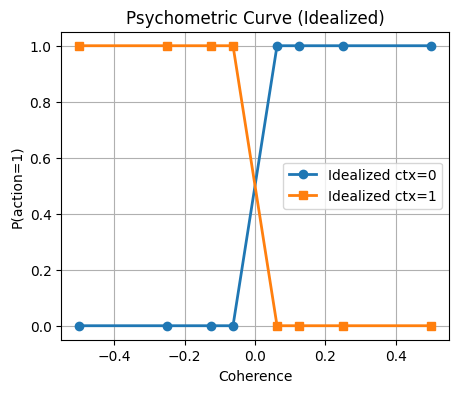

In [3]:
cohs = np.array(coherences)
probs_ctx0 = []
probs_ctx1 = []

for coh in cohs:
    # ctx=0
    idxs0 = [i for i, p in enumerate(params_sel) if abs(p[1] - coh) < 1e-8 and p[0] == 0]
    if len(idxs0) == 0:
        probs_ctx0.append(np.nan)
    else:
        y_last0 = [Y_sel[i, -1, 0].item() for i in idxs0]
        probs_ctx0.append(np.mean(np.array(y_last0) > 0.5))
    # ctx=1
    idxs1 = [i for i, p in enumerate(params_sel) if abs(p[1] - coh) < 1e-8 and p[0] == 1]
    if len(idxs1) == 0:
        probs_ctx1.append(np.nan)
    else:
        y_last1 = [Y_sel[i, -1, 0].item() for i in idxs1]
        probs_ctx1.append(np.mean(np.array(y_last1) > 0.5))

cohs = np.sort(np.array(coherences))
plt.figure(figsize=(5,4))
plt.plot(cohs, probs_ctx0, 'o-', lw=2, label='Idealized ctx=0')
plt.plot(cohs, probs_ctx1, 's-', lw=2, label='Idealized ctx=1')
plt.xlabel('Coherence')
plt.ylabel('P(action=1)')
plt.title('Psychometric Curve (Idealized)')
plt.legend()
plt.grid(True)
plt.show()

Training...
initial loss: 0.506
tensor([[[ 0.0000e+00,  4.3387e-02],
         [ 0.0000e+00, -1.2800e-02],
         [ 0.0000e+00,  1.0724e-02],
         ...,
         [ 2.3953e-02, -4.9852e-03],
         [-3.8021e-02, -1.8823e-02],
         [ 9.3961e-03, -1.7071e-04]],

        [[ 1.0000e+00,  3.2670e-02],
         [ 1.0000e+00,  8.3386e-02],
         [ 1.0000e+00, -2.3958e-02],
         ...,
         [-4.1310e-02, -5.1691e-02],
         [-7.7066e-02,  4.6711e-04],
         [ 5.2720e-02,  3.1166e-02]],

        [[ 1.0000e+00,  9.7360e-02],
         [ 1.0000e+00,  8.0717e-03],
         [ 1.0000e+00, -3.9841e-02],
         ...,
         [-8.7891e-02, -2.8242e-03],
         [ 2.2950e-02,  3.0470e-02],
         [ 2.3628e-03, -2.6608e-02]],

        ...,

        [[ 1.0000e+00,  9.6716e-02],
         [ 1.0000e+00, -1.3359e-01],
         [ 1.0000e+00, -1.9409e-02],
         ...,
         [ 1.3775e-03,  6.1038e-02],
         [ 3.7817e-03, -7.8636e-02],
         [-3.8134e-02,  4.0340e-02]],

  

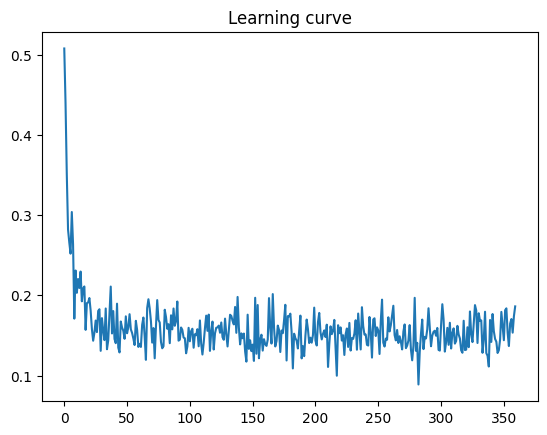

Validation Loss: 0.1499, Accuracy: 0.9898


In [ ]:
# 4. Training a Full-Rank RNN on the XOR Task

import torch
import numpy as np
import matplotlib.pyplot as plt
from low_rank_rnns.modules import FullRankRNN, loss_mse, train, accuracy_general
from low_rank_rnns.helpers import map_device
from math import floor
import torch.nn as nn
loss_fn = nn.BCEWithLogitsLoss()

# —— Task & data preparation (same as before)
deltaT = 20.
t_ctx     = 400
t_stim    = 800
t_dec     = 200
t_ctx_steps  = floor(t_ctx/deltaT)
t_stim_steps = floor(t_stim/deltaT)
t_dec_steps  = floor(t_dec/deltaT)
t_total      = t_ctx_steps + t_stim_steps + t_dec_steps


# 4.1 Hyperparameters
INPUT_SIZE  = 2      # context + coherence
HIDDEN_SIZE = 512    # 512 hidden units
OUTPUT_SIZE = 1      # scalar readout
NOISE_STD   = 0.02   # recurrent noise
ALPHA       = 0.1    # dt/tau

# 4.2 Instantiate full-rank network
net = FullRankRNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    output_size=OUTPUT_SIZE,
    noise_std=NOISE_STD,
    alpha=ALPHA,
    # FullRankRNN doesn't need rank parameter
    train_wi=True,
    train_wo=True,
    train_wrec=True,
    train_h0=False,
)

# 4.3 Generate & split data
X_all, Y_all, M_all, params_all = generate_xor_batch(n_trials=2000, std=0.05)
split = int(0.8 * X_all.shape[0])
X_tr, X_val = X_all[:split], X_all[split:]
Y_tr, Y_val = Y_all[:split], Y_all[split:]
M_tr, M_val = M_all[:split], M_all[split:]

# 4.4 Move to GPU/CPU
X_tr, Y_tr, M_tr, X_val, Y_val, M_val = map_device(
    [X_tr, Y_tr, M_tr, X_val, Y_val, M_val], net
)

# 4.5 Training function wrapper
def run_training():
    train(
        net,
        X_tr, Y_tr, M_tr,
        n_epochs=30,
        lr=1e-3,
        batch_size=128,
        plot_learning_curve=True,
        plot_gradient=False,
        cuda=torch.cuda.is_available(),
        keep_best=True,
    )
    # Validation set evaluation
    with torch.no_grad():
        out = net(X_val)
        val_loss = loss_mse(out, Y_val, M_val).item()
        val_acc  = accuracy_general(out, Y_val, M_val).item()
        print(f"Validation Loss: {val_loss:.4f}, Accuracy: {val_acc:.4f}")

# 4.6 Run training
if __name__ == '__main__':
    run_training()

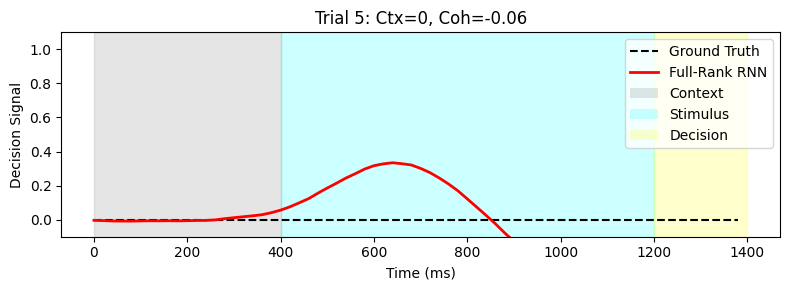

In [ ]:
# 4.7 Single trial visualization
net.eval()
trial_idx = 5
ctx, coh, _ = params_all[split + trial_idx]
x, y_true, _ = make_single_xor_trial(ctx, coh)
with torch.no_grad():
    y_pred = net(x)[0, :, 0].cpu().numpy()
    y_true = y_true[0, :, 0].numpy()
t = np.arange(t_total) * deltaT

plt.figure(figsize=(8,3))
plt.step(t, y_true, where='post', label='Ground Truth', ls='--', c='k')
plt.plot(t, y_pred, label='Full-Rank RNN', c='r', lw=2)
for name, s, e, color in [
    ('Ctx', 0, t_ctx_steps, 'gray'),
    ('Stim', t_ctx_steps, t_ctx_steps+t_stim_steps, 'cyan'),
    ('Dec', t_ctx_steps+t_stim_steps, t_total, 'yellow'),
]:
    plt.axvspan(s*deltaT, e*deltaT, color=color, alpha=0.2)
# Manually create legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], label='Ground Truth', linestyle='--', color='k'),
    Line2D([0], [0], label='Full-Rank RNN', color='r', linewidth=2),
    Patch(facecolor='gray', alpha=0.2, label='Context'),
    Patch(facecolor='cyan', alpha=0.2, label='Stimulus'),
    Patch(facecolor='yellow', alpha=0.2, label='Decision')
]
plt.xlabel('Time (ms)')
plt.ylabel('Decision Signal')
plt.ylim(-0.1, 1.1)
plt.legend(handles=legend_elements, loc='upper right')
plt.title(f'Trial {trial_idx}: Ctx={ctx}, Coh={coh:.2f}')
plt.tight_layout()
plt.show()

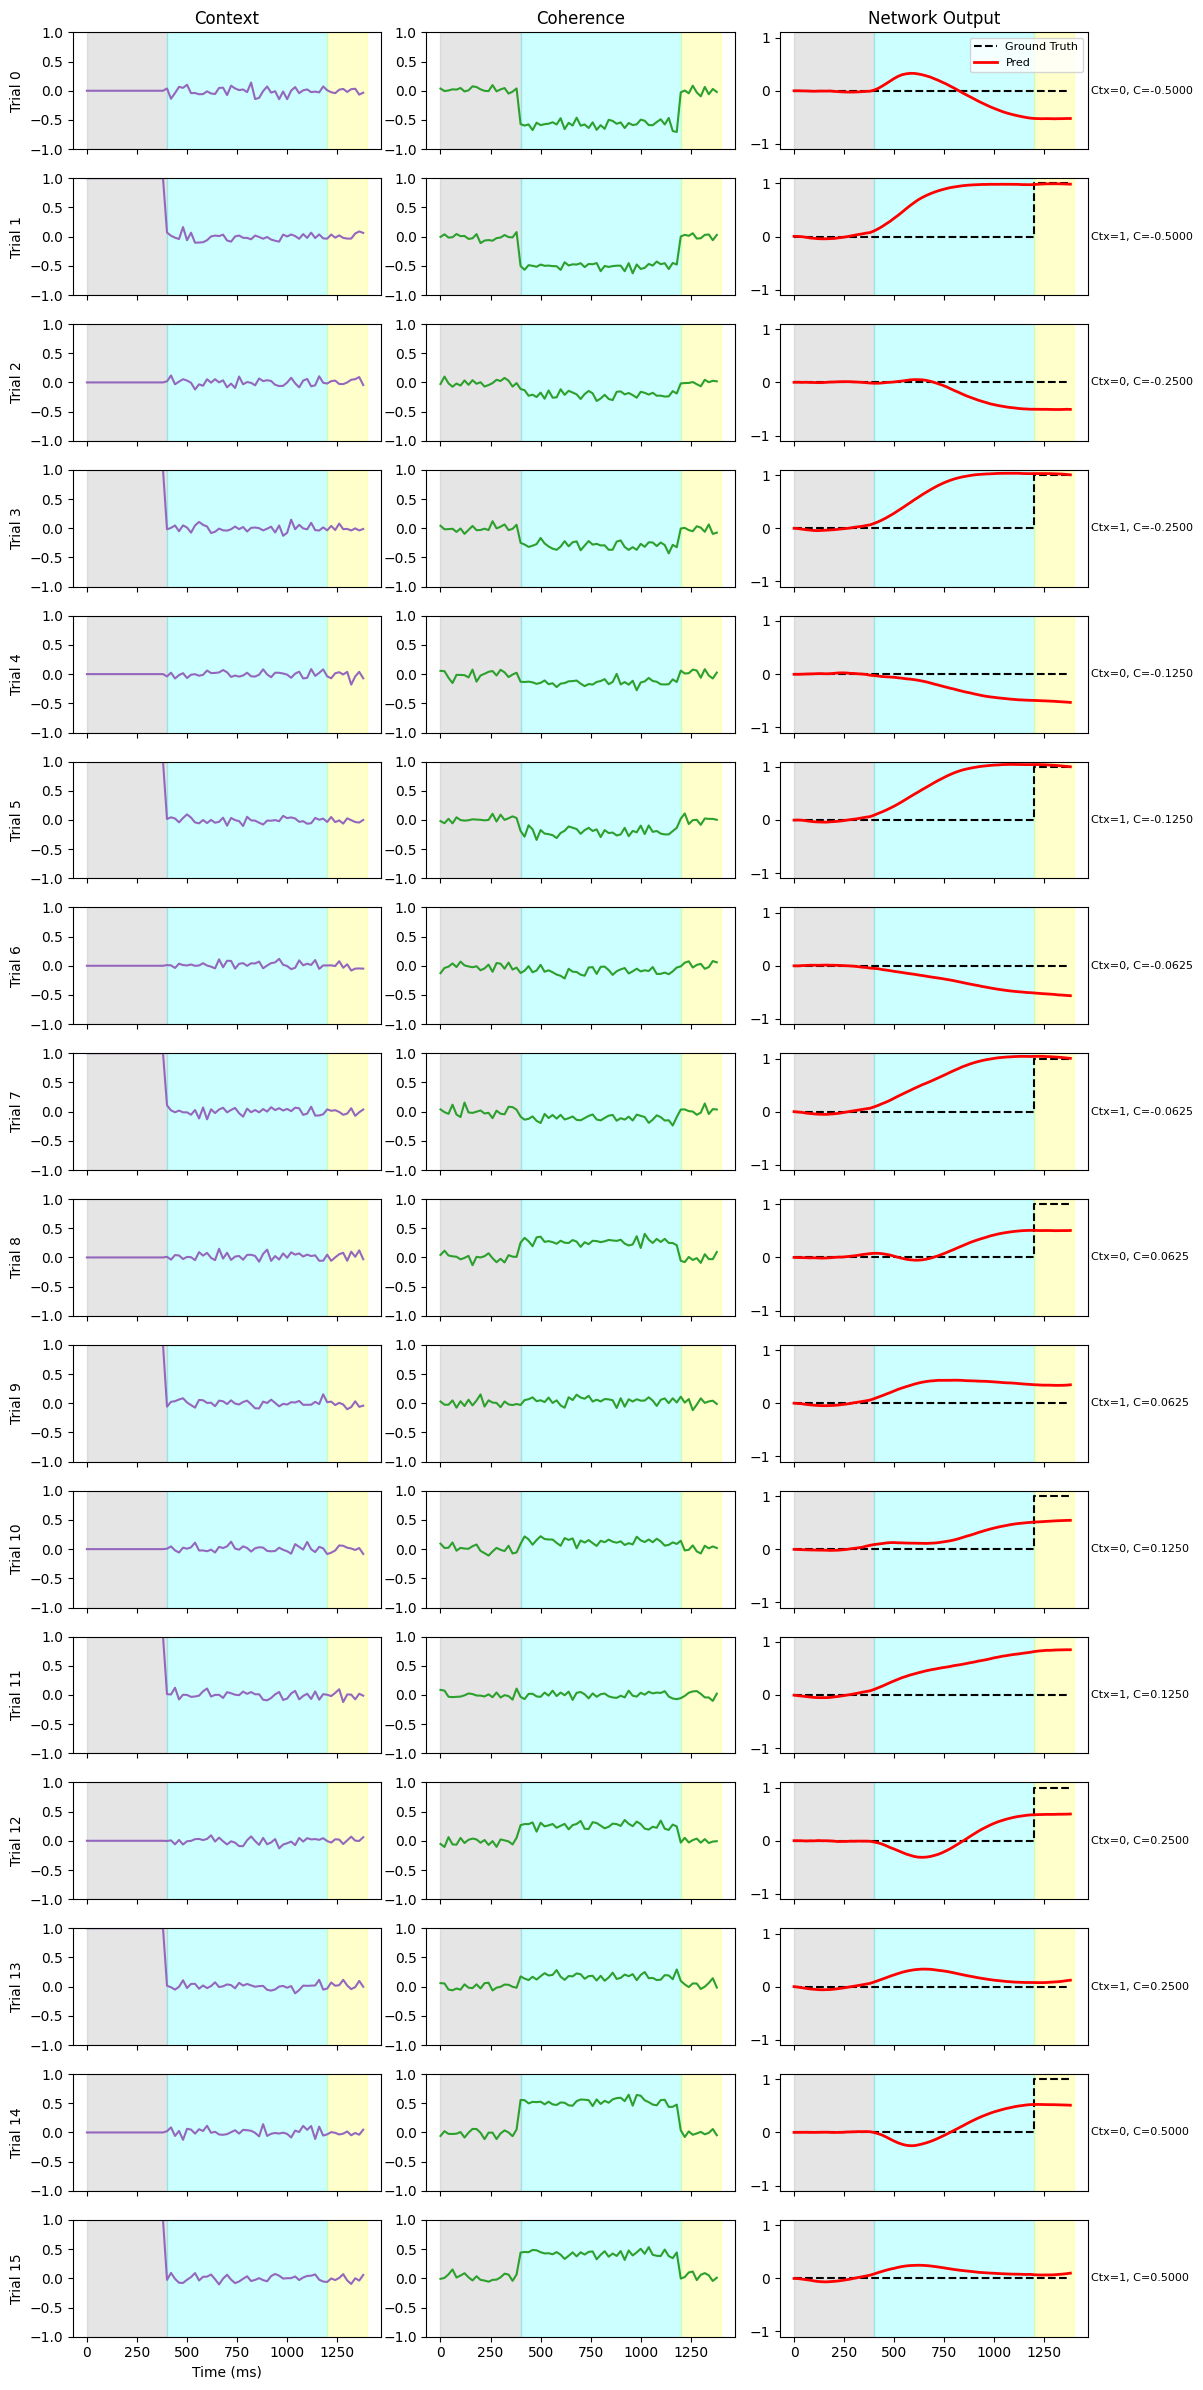

In [ ]:
# Generate 16 idealized trials
n_sel = len(coherences) * 2
X_sel = torch.zeros(n_sel, t_total, 2)
Y_sel = torch.zeros(n_sel, t_total, 1)
params_sel = []
idx = 0
for coh in coherences:
    for ctx in [0, 1]:
        x, y, _ = make_single_xor_trial(ctx, float(coh))
        X_sel[idx] = x
        Y_sel[idx] = y
        params_sel.append((ctx, float(coh), int(y[0, -1, 0])))
        idx += 1

# Network prediction
net.eval()
with torch.no_grad():
    Y_pred = net(X_sel).cpu().numpy()[:, :, 0]
# Take the last frame of the decision period



# Visualization
plot_multiple_xor_pred(X_sel, Y_sel, Y_pred, params_sel, list(range(n_sel)),
                       deltaT, t_ctx_steps, t_stim_steps, t_total)

coh -0.5
coh -0.25
coh -0.125
coh -0.0625
coh 0.0625
coh 0.125
coh 0.25
coh 0.5


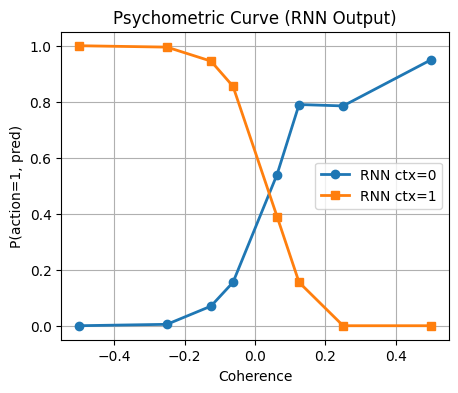

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n_rep = 200  # Number of repetitions for each (coh, ctx)
cohs = np.sort(coherences)
probs_pred_ctx0 = []
probs_pred_ctx1 = []

for coh in cohs:
    # ctx = 0
    outs0 = []
    for _ in range(n_rep):
        x, _, _ = make_single_xor_trial(0, coh, std=0.05, coh_noise_mean=0.1, coh_noise_std=0.05)  # Common placeholder usage, only using x
        with torch.no_grad():
            y_pred = net(x).cpu().numpy()[0, -1, 0]  # Take the last frame of decision period
        outs0.append(y_pred > 0.5)  # Threshold to determine action=1
    probs_pred_ctx0.append(np.mean(outs0))

    # ctx = 1
    outs1 = []
    print('coh',coh)
    for _ in range(n_rep):
        x, _, _ = make_single_xor_trial(1, coh, std=0.05, coh_noise_mean=0.1,coh_noise_std=0.05)
        with torch.no_grad():
            y_pred = net(x).cpu().numpy()[0, -1, 0]
        outs1.append(y_pred > 0.5)
    probs_pred_ctx1.append(np.mean(outs1))

In [8]:
# Extract parameters from the trained network
W_rec = net.wrec.detach().cpu().numpy()
W_in  = net.wi_full.detach().cpu().numpy()
W_out = net.wo_full.detach().cpu().numpy()
alpha = net.alpha
noise_std = net.noise_std
nonlinearity = np.tanh 

def simulate_rnn_dynamics(W_rec, W_in, W_out, alpha, nonlinearity, x_seq, h0=None, noise_std=0.0):
    """
    Simulate the RNN dynamics in numpy for analysis.
    x_seq: shape (T, input_dim)
    h0: initial hidden state, shape (hidden_dim,)
    Returns: h_seq (T, hidden_dim), r_seq (T, hidden_dim), y_seq (T, output_dim)
    """
    T, input_dim = x_seq.shape
    hidden_dim = W_rec.shape[0]
    output_dim = W_out.shape[1]
    h_seq = np.zeros((T, hidden_dim))
    r_seq = np.zeros((T, hidden_dim))
    y_seq = np.zeros((T, output_dim))
    h = np.zeros(hidden_dim) if h0 is None else h0.copy()
    for t in range(T):
        noise = np.random.randn(hidden_dim) * noise_std
        r = nonlinearity(h)
        h = h + noise + alpha * (-h + r @ W_rec.T + x_seq[t] @ W_in)
        y = r @ W_out
        h_seq[t] = h
        r_seq[t] = r
        y_seq[t] = y
    return h_seq, r_seq, y_seq


In [ ]:
def flatten_trials(all_r_mean):
    """
    Flatten all time steps of the four conditions, return shape=(4*t_total, H)
    """
    N, T, H = all_r_mean.shape
    X = all_r_mean.reshape(N * T, H)
    return X

def run_pca(all_r_mean, n_components=3):
    """
    PCA dimensionality reduction: all_r (N, T, H) → Z_trials (N, T, 3)
    """

Explained variance ratios: [0.33497256 0.32004943 0.2216515 ]


In [12]:
# Extract parameters from the trained network
W_rec = net.wrec.detach().cpu().numpy()
W_in  = net.wi_full.detach().cpu().numpy()
W_out = net.wo_full.detach().cpu().numpy()
alpha = net.alpha
noise_std = net.noise_std
nonlinearity = np.tanh 

In [ ]:
def velocity_field_with_input(hidden_init, Umat, x_t,pca_remains,n_grid):
    """
    Calculate velocity field on PC1–PC2 plane given input x_t.
    - pts3: (M,3) low-dimensional points
    - x_t:   (2,)  input vector [context, coherence] at time t
    Returns:
    - U: shape (n_grid,n_grid) corresponding to PC1 component
    - V: shape (n_grid,n_grid) corresponding to PC2 component
    """
    velocity = np.zeros((np.shape(hidden_init)[0], 2))
    for i in range(np.shape(hidden_init)[0]):
        init_pc12 = np.squeeze(hidden_init[i,:])  # Extract PC1 and PC2 coordinates of the i-th grid point
        # init_pc12 shape: (2,) - [PC1_value, PC2_value]
        pts_merge = np.concatenate((init_pc12, pca_remains), axis=0)  # init_pc12: (2,) - PC1, PC2 coordinates 
        # pca_remains: (278,) - coordinates from PC3 to PC280
        # pts_merge: (280,) - complete PCA coordinate vector

        # 1) Reconstruct high-dimensional hidden state h
        ##@YS ??? 
        r = pts_merge.dot(Umat)            # (M,H)
        if np.abs(r).max() > 1:
            r = np.clip(r, -0.999, 0.999)
        h = np.arctanh(r)
        # h = pts_merge.dot(Umat)  #(M,H)
        # r = np.tanh(h)                # (M,H)
        
        # 2) Calculate dh = -h + W_rec·r + W_in·x_t
        #    W_rec·r^T = r.dot(W_rec.T)
        #    W_in·x_t = x_t.dot(W_in)  gives (H,)
        dh = -h + r.dot(W_rec.T) + x_t.dot(W_in)
        # 3) Euler step
        h_new = h + alpha * dh
        r_new = np.tanh(h_new)
        # 4) Activity velocity dr = r_new - r
        dr = r_new - r               # (M,H)
        # 5) Project to PCA space: dr·Umat^T → (M,3)
        v_pc = dr.dot(Umat.T)        # (M,3)
        velocity[i, :] = v_pc[:2]
    # Extract PC1, PC2 components and reshape
    U = velocity[:,0].reshape(n_grid,n_grid)
    V = velocity[:,1].reshape(n_grid,n_grid)
    # velocity = v_pc[:, :2].reshape(n_grid, n_grid, 2).transpose(2,0,1)
    return U, V

In [ ]:
_, pca_full = run_pca(all_r_mean, n_components=280)
conds = [(0, 0.5), (0, -0.5),(1,-0.5), (1, 0.5)]  # (ctx, coh) pairs
x_seqs = []
for ctx, coh in conds:
    x, _, _ = make_single_xor_trial(ctx, coh, std=0.0,coh_noise_std=0.0)
    x_seqs.append(x.squeeze(0).cpu().numpy())
    h0, r0, y0 = simulate_rnn_dynamics(W_rec, W_in, W_out, alpha, nonlinearity, x_seqs[0], h0=None, noise_std=0.0)
    r0_pca = pca_full.transform(r0)  # (t_total, 3)

r0_pca = pca.transform(r0)  # (1, 3)
init_pc12 = np.array([r0_pca[0, 0], r0_pca[0, 1]])
pca_remains = r0_pca[0,2:]
pca_merge = np.concatenate((init_pc12, pca_remains), axis=0)

# 1) Flatten
N, T, H = all_r_mean.shape
X_flat = all_r_mean.reshape(N * T, H)            # (4*t_total, H)

# 2) Call PCA transform
Z_flat = pca_full.transform(X_flat)               # (4*t_total, n_components)

# 3) Reshape back
Z_trials_full = Z_flat.reshape(N, T, -1)          # (4, t_total, n_components)           


r0_pca[t_total-1,2]

Explained variance ratios: [3.34972441e-01 3.20049375e-01 2.21651509e-01 5.31310253e-02
 3.61047946e-02 9.87665355e-03 8.83640908e-03 6.66395249e-03
 2.23282003e-03 1.73954573e-03 8.17882363e-04 7.31737353e-04
 6.11374271e-04 4.15903603e-04 3.49796173e-04 2.39086323e-04
 1.91218307e-04 1.54170208e-04 1.35613460e-04 1.23830599e-04
 8.39124623e-05 7.81377457e-05 6.52481613e-05 5.74967053e-05
 5.38253080e-05 4.54284054e-05 3.53452742e-05 3.32239724e-05
 2.93655139e-05 2.82429010e-05 2.58300606e-05 2.11441311e-05
 2.06495151e-05 1.79295694e-05 1.77323000e-05 1.65202146e-05
 1.45762870e-05 1.29329246e-05 1.22380143e-05 1.05877862e-05
 1.02522918e-05 9.40104928e-06 9.00050600e-06 8.29771852e-06
 8.08067398e-06 7.76316938e-06 6.90808929e-06 6.32542151e-06
 6.12840904e-06 6.04205025e-06 5.71462988e-06 5.30224906e-06
 5.21971515e-06 5.14782141e-06 4.98660302e-06 4.60573710e-06
 4.55359032e-06 4.21255845e-06 4.07135121e-06 3.95655434e-06
 3.62896594e-06 3.59839100e-06 3.42762860e-06 3.34722995e-

np.float64(-10.948431084818125)

In [ ]:
# Extract network weights and PCA basis
W_rec = net.wrec.detach().cpu().numpy()
W_in  = net.wi_full.detach().cpu().numpy()   # shape (2, H)
Umat  = pca_full.components_                     # shape (3, H)
W_out = net.wo_full.detach().cpu().numpy()
alpha = net.alpha
noise_std = net.noise_std
nonlinearity = np.tanh 

# 2) Generate input sequences for four trials
conds = [(0, -0.5), (0, 0.5), (1, -0.5), (1, 0.5)]
x_seqs = []
rpca_seqs = []
for ctx, coh in conds:
    x, _, _ = make_single_xor_trial(ctx, coh, std=0.0, coh_noise_mean = 0.0,coh_noise_std=0.0)
    x0 = x.squeeze(0).cpu().numpy()  # shape (t_total, 2)
    x_seqs.append(x0)  # shape (t_total, 2)